# 02 — ¿Qué edades representa la curva empírica?

EDA diagnóstico independiente. Lee proyecciones y curvas ya calculadas de 2021–2026 y la base analítica; **no cambia curvas, reglas de cero, modelos ni pronósticos**. Se profundiza en DINO amarillo de GAITANA para el objetivo 31 de agosto de 2026, usando el plano del 13 de julio.

Se distingue: cero observado; edad anterior a la primera edad observada; edad anterior al primer corte positivo observado; hueco dentro del rango observado; edad posterior al rango. Un mínimo observado NO es una edad biológica de inicio: depende de seguimiento, cobertura y representatividad. Un piloto aislado tampoco demuestra un patrón general.

Las curvas de cada plano ya usan su propia ventana histórica de 78 semanas, sin cortes futuros. Las ediciones anuales pueden repetir historia: los totales de proyección representan exposiciones cohorte–plano–semana objetivo, **no plantas ni camas únicas**. La segunda parte vuelve a los casos con producción observada y clasifica qué edades de cohortes no están representadas por la curva; no es una auditoría de pérdida de producción.

Salidas: `resultados_todos_los_anios/eda_edades_sin_cobertura/`. Ejecutar con `entorno_tesis`; no requiere ejecutar otros notebooks si existen sus salidas actuales.


**Lectura correcta:** este notebook describe qué edades están representadas en las curvas piloto para las cohortes de cada plano. La producción real se conserva en la base analítica. Cuando la curva no representa todas las edades, el sistema no usa un total teórico parcial y continúa con la ruta basada en producción reciente. Esto es un límite normal de una curva empírica y no equivale a una falla de unión ni a pérdida de registros.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'Datos_analiticos_proyecto').exists())
PROY=ROOT/'Notebooks/Proyecciones Teoricas Propias/resultados_todos_los_anios'
OUT=PROY/'eda_edades_sin_cobertura'; OUT.mkdir(exist_ok=True)
KEY=['finca','producto','color','variedad']
def normalizar(s):
    return (s.astype('string').str.strip().str.upper().str.normalize('NFKD')
            .str.encode('ascii',errors='ignore').str.decode('ascii')
            .str.replace(r'\s+',' ',regex=True).replace('',pd.NA))
base=pd.read_parquet(ROOT/'Datos_analiticos_proyecto/modelo_con_proyecciones_teoricas/base_analitica_proyecciones.parquet')
observados=base.loc[base.y.notna()].copy()
resumen_base=observados.groupby('motivo_cobertura',dropna=False).size().rename('casos').to_frame()
resumen_base['porcentaje']=100*resumen_base.casos/len(observados)
display(resumen_base)
print('Denominador:',len(observados),'casos con producción real, no inventario físico.')


,casos,porcentaje
motivo_cobertura,,
cohortes_sin_curva,158453,75.095853
curva_completa,46051,21.825015
sin_pareja_comercial_u_objetivo,5523,2.617523
sin_snapshot_disponible,974,0.461609


Denominador: 211001 casos con producción real, no inventario físico.


## 1. Edades representadas por las curvas en todas las ediciones

Se comparan las edades requeridas con el rango de la curva que realmente estaba disponible en cada plano. Las clases tempranas son **candidatas a revisión**, no autorizaciones para rellenar con cero. Para un hueco interior ya existe evidencia de rendimiento a otras edades menores/mayores; eso no permite interpolar automáticamente el valor faltante.


In [2]:
estados=[]; edades=[]; grupos=[]; exposiciones=[]
cols=['plano','fecha_plano','finca','producto','color','variedad','clave_curva','fecha_siembra','semana_proyeccion','edad','plantas','estado']
llave=['plano','semana_objetivo']+['union_'+c for c in KEY]
for folder in sorted(p for p in PROY.iterdir() if p.is_dir() and p.name.isdigit()):
    anio=int(folder.name)
    q=pd.read_parquet(folder/'proyecciones_teoricas.parquet',columns=cols)
    cv=pd.read_parquet(folder/'curvas.parquet')
    limites=cv.groupby(['fecha_plano','clave_curva']).agg(edad_min=('edad','min'),edad_max=('edad','max'))
    positivas=cv.loc[cv.rendimiento_curva.gt(0)].groupby(['fecha_plano','clave_curva']).edad.min().rename('primera_edad_positiva')
    limites=limites.join(positivas).reset_index()
    z=q.groupby('estado',dropna=False).agg(exposiciones=('estado','size'),plantas_expuestas=('plantas','sum')).reset_index()
    estados.append(z.assign(edicion=anio))
    bad=q.loc[~q.estado.isin(['proyectada','siembra_posterior'])].copy()
    bad=bad.merge(limites,on=['fecha_plano','clave_curva'],how='left',validate='many_to_one')
    edad_falta=bad.estado.eq('edad_fuera_de_curva')
    bad['diagnostico']=bad.estado.astype('string')
    bad.loc[edad_falta,'diagnostico']=np.select([
        bad.loc[edad_falta,'edad_min'].isna(),
        bad.loc[edad_falta,'edad'].lt(bad.loc[edad_falta,'edad_min']).fillna(False),
        bad.loc[edad_falta,'edad'].gt(bad.loc[edad_falta,'edad_max']).fillna(False),
        bad.loc[edad_falta,'primera_edad_positiva'].isna(),
        bad.loc[edad_falta,'edad'].lt(bad.loc[edad_falta,'primera_edad_positiva']).fillna(False)],
        ['sin_rango_observado','anterior_primera_edad_observada','posterior_ultima_edad_observada',
         'hueco_sin_positivos_observados','hueco_antes_primer_positivo'],default='hueco_en_rango_con_produccion')
    ee=bad.groupby('diagnostico',dropna=False).agg(exposiciones=('estado','size'),plantas_expuestas=('plantas','sum')).reset_index()
    edades.append(ee.assign(edicion=anio))
    for c in KEY:
        valores=bad[c].drop_duplicates()
        mapa=dict(zip(valores,normalizar(valores)))
        bad['union_'+c]=bad[c].map(mapa).astype('string')
    bad=bad.rename(columns={'semana_proyeccion':'semana_objetivo'})
    grupos.append(bad.groupby(llave+['diagnostico'],dropna=False).size().rename('grupos_sin_cobertura').reset_index())
    if anio==2026:
        faltantes_2026=bad.copy(); proyecciones_2026=q.copy(); curvas_2026=cv.copy()
    print('Edición',anio,':',len(q),'exposiciones;',len(bad),'sin cobertura')
estados=pd.concat(estados,ignore_index=True); edades=pd.concat(edades,ignore_index=True)
grupos=pd.concat(grupos,ignore_index=True)
assert not grupos.duplicated(llave+['diagnostico']).any()
display(edades.pivot(index='edicion',columns='diagnostico',values='exposiciones').fillna(0).astype(int))
por_producto=faltantes_2026.groupby(['producto','diagnostico']).agg(exposiciones=('estado','size'),plantas_expuestas=('plantas','sum')).reset_index()
display(por_producto)
grupos.to_parquet(OUT/'diagnostico_edades_por_grupo.parquet',index=False)


Edición 2021 : 1684910 exposiciones; 399794 edad no representada por curva


Edición 2022 : 1510500 exposiciones; 361786 edad no representada por curva


Edición 2023 : 1508460 exposiciones; 311923 edad no representada por curva


Edición 2024 : 1567170 exposiciones; 231922 edad no representada por curva


Edición 2025 : 1644580 exposiciones; 287720 edad no representada por curva


Edición 2026 : 1064620 exposiciones; 281365 edad no representada por curva


diagnostico,anterior_primera_edad_observada,hueco_antes_primer_positivo,hueco_en_rango_con_produccion,hueco_sin_positivos_observados,plantas_invalidas,posterior_ultima_edad_observada,sin_fecha_siembra,sin_historia_variedad,sin_variedad_maestra
edicion,,,,,,,,,
2021,74989,7962,33148,147,0,64118,10,143810,75610
2022,80619,3773,36340,0,20,65209,0,167445,8380
2023,96803,4135,26831,144,0,59740,0,120760,3510
2024,79471,2050,31256,136,0,55519,0,59880,3610
2025,116099,499,38938,0,0,49274,0,82550,360
2026,135618,2191,25647,0,0,42289,0,75610,10


,producto,diagnostico,exposiciones,plantas_expuestas
0,Achillea,posterior_ultima_edad_observada,780,55000
1,Amazon,anterior_primera_edad_observada,382,395200
2,Amazon,hueco_en_rango_con_produccion,766,777200
3,Amazon,posterior_ultima_edad_observada,675,764600
4,Barbatus,anterior_primera_edad_observada,2787,3209140
5,Barbatus,hueco_en_rango_con_produccion,2026,2036000
6,Barbatus,posterior_ultima_edad_observada,3800,3731450
7,Barbatus,sin_historia_variedad,1310,1279100
8,Carnation,anterior_primera_edad_observada,76553,279428300
9,Carnation,hueco_antes_primer_positivo,2188,6083560


## 2. ¿En qué casos se puede usar la referencia directa de curva?

Este indicador se calcula en la base analítica y marca los casos donde la curva no representa todas las edades de sus cohortes. La clasificación **excluyente por caso** distingue si las edades no representadas son tempranas, huecos interiores, edades posteriores o una mezcla. No cuenta producción perdida ni cruces fallidos. Solo las edades tempranas son candidatas a revisar una posible regla preproductiva; no demuestra que su rendimiento sea cero.


In [3]:
totales=grupos.groupby(llave,dropna=False).grupos_sin_cobertura.sum().rename('reconstruidos').reset_index()
casos=observados.merge(totales,on=llave,how='left',validate='many_to_one')
pendiente=casos.motivo_cobertura.eq('cohortes_sin_curva')
verificados=np.isclose(casos.loc[pendiente,'sin_cobertura'],casos.loc[pendiente,'reconstruidos'],equal_nan=False)
assert verificados.all(), f'No concuerdan {int((~verificados).sum())} casos: revisar normalización antes de interpretar.'
def clasificar_caso(g):
    causas=set(g.diagnostico)
    if causas.issubset({'anterior_primera_edad_observada','hueco_antes_primer_positivo'}):return 'solo_edades_tempranas_por_verificar'
    if causas=={'hueco_en_rango_con_produccion'}:return 'solo_huecos_en_rango'
    if causas=={'posterior_ultima_edad_observada'}:return 'solo_edades_posteriores'
    if causas.issubset({'anterior_primera_edad_observada','hueco_antes_primer_positivo','hueco_en_rango_con_produccion','posterior_ultima_edad_observada','hueco_sin_positivos_observados'}):return 'mezcla_de_edades_sin_soporte'
    return 'otros_estados_o_combinaciones'
clases=grupos.groupby(llave,dropna=False)[['diagnostico']].apply(clasificar_caso).rename('clase_edades').reset_index()
casos=casos.merge(clases,on=llave,how='left',validate='many_to_one')
casos['diagnostico_final']=casos.motivo_cobertura.astype('string')
casos.loc[pendiente,'diagnostico_final']=casos.loc[pendiente,'clase_edades']
resumen_casos=casos.groupby('diagnostico_final').size().rename('casos').to_frame()
resumen_casos['porcentaje_total']=100*resumen_casos.casos/len(casos)
resumen_casos['porcentaje_incompletos']=np.where(resumen_casos.index.str.startswith(('solo_','mezcla_','otros_')),100*resumen_casos.casos/pendiente.sum(),np.nan)
assert resumen_casos.casos.sum()==len(observados)
display(resumen_casos)
print('Verificación exacta:',int(pendiente.sum()),'casos incompletos explicados por sus grupos faltantes.')


,casos,porcentaje_total,porcentaje_incompletos
diagnostico_final,,,
curva_completa,46051,21.825015,NaN
mezcla_de_edades_sin_soporte,33483,15.868645,21.131187
otros_estados_o_combinaciones,43859,20.786157,27.679501
sin_pareja_comercial_u_objetivo,5523,2.617523,NaN
sin_snapshot_disponible,974,0.461609,NaN
solo_edades_posteriores,29168,13.823631,18.407982
solo_edades_tempranas_por_verificar,34199,16.207980,21.583056
solo_huecos_en_rango,17744,8.409439,11.198273


Verificación exacta: 158453 casos donde no aplica la referencia directa explicados por sus grupos faltantes.


## 3. DINO: revisar los dos grupos y el soporte real de sus edades

La semana objetivo es 31 de agosto–6 de septiembre de 2026; el plano utilizado tiene fecha 13 de julio. Se consulta exactamente la historia de las 78 semanas anteriores a ese plano. Los primeros positivos por piloto son **primeros cortes observados dentro de la ventana**, no inicios biológicos garantizados.


,fecha_siembra,edad,plantas,estado
906865,2026-05-12,16,5040,edad_fuera_de_curva
906866,2026-07-02,9,13104,edad_fuera_de_curva


,observaciones,ceros,positivos,pilotos,tallos
edad,,,,,
0,0,0,0,0,NaN
1,0,0,0,0,NaN
2,0,0,0,0,NaN
3,0,0,0,0,NaN
4,0,0,0,0,NaN
5,0,0,0,0,NaN
6,0,0,0,0,NaN
7,0,0,0,0,NaN
8,0,0,0,0,NaN


,primera_edad_positiva_observada
count,40.0
mean,28.325
std,9.288503
min,14.0
25%,23.0
50%,24.0
75%,29.0
max,52.0


,archivo,referencia,id_piloto,fila_excel_est,fecha_siembra,fecha_corte,edad,edad_original,diferencia_edad,corte,plantas
350243,2026/Estadisticas Miniclavel 2026.xlsx,dino-30-103,28042.0,218565,2025-01-15,2025-06-02,20,20.0,0.0,0.0,1200.0
350264,2026/Estadisticas Miniclavel 2026.xlsx,dino-30-103,28042.0,218586,2025-01-15,2025-06-09,21,21.0,0.0,0.0,1200.0
365498,2026/Estadisticas Miniclavel 2026.xlsx,dino-16-175,28402.0,234608,2025-11-18,2026-02-23,14,14.0,0.0,288.0,1330.0


,edad,fuente,filas,ceros,positivos
0,9,utilizable_ventana,0,0,0
1,9,auditoria_ventana,0,0,0
2,9,utilizable_todo_pasado_edicion,0,0,0
3,16,utilizable_ventana,0,0,0
4,16,auditoria_ventana,0,0,0
5,16,utilizable_todo_pasado_edicion,0,0,0


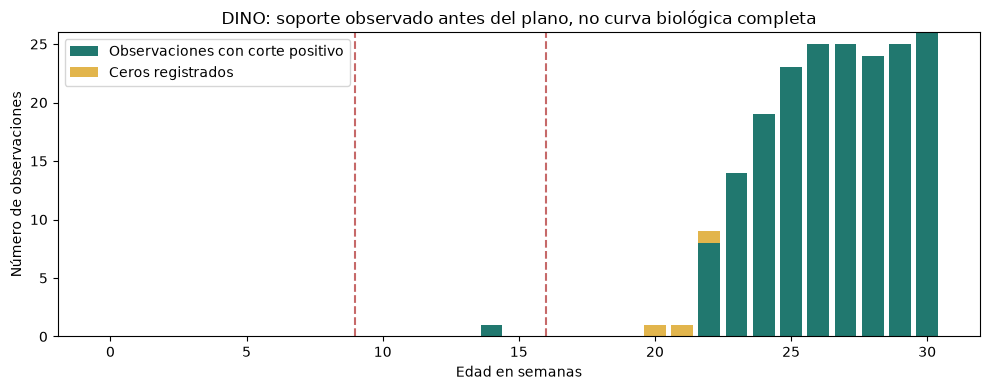

Primera edad positiva observada: 14


In [4]:
clave='COMERCIAL|MINICARNATION|YELLOW|DINO'
fecha=pd.Timestamp('2026-07-13'); objetivo=pd.Timestamp('2026-08-31')
dino=proyecciones_2026.loc[proyecciones_2026.clave_curva.eq(clave)&proyecciones_2026.finca.eq('GAITANA')&proyecciones_2026.fecha_plano.eq(fecha)&proyecciones_2026.semana_proyeccion.eq(objetivo)].copy()
dino_faltantes=dino.loc[~dino.estado.isin(['proyectada','siembra_posterior'])]
display(dino_faltantes[['fecha_siembra','edad','plantas','estado']])
est=pd.read_parquet(PROY/'2026/estadisticas.parquet')
hist=est.loc[est.clave_curva.eq(clave)&est.fecha_corte.ge(fecha-pd.Timedelta(weeks=78))&est.fecha_corte.lt(fecha)].copy()
soporte=hist.groupby('edad').agg(observaciones=('corte','size'),ceros=('corte',lambda x:x.eq(0).sum()),positivos=('corte',lambda x:x.gt(0).sum()),pilotos=('id_piloto','nunique'),tallos=('corte','sum'))
edades_objetivo=range(0,31)
soporte=soporte.reindex(edades_objetivo).rename_axis('edad')
soporte[['observaciones','ceros','positivos','pilotos']]=soporte[['observaciones','ceros','positivos','pilotos']].fillna(0).astype(int)
# Tallos se mantiene vacío cuando no hay observación; no se fabrica producción cero.
display(soporte)
min_pos=hist.loc[hist.corte.gt(0),'edad'].min()
primeros=hist.loc[hist.corte.gt(0)].groupby('id_piloto').edad.min().rename('primera_edad_positiva_observada').reset_index()
display(primeros.primera_edad_positiva_observada.describe().to_frame())
temprano=hist.loc[hist.edad.le(21),['archivo','referencia','id_piloto','fila_excel_est','fecha_siembra','fecha_corte','edad','edad_original','diferencia_edad','corte','plantas']].copy()
display(temprano)
# Comprobar si 9/16 fueron excluidas por calidad, o existen fuera de la ventana.
aud=pd.read_parquet(PROY/'2026/estadisticas_auditoria.parquet')
checks=[]
for edad in [9,16]:
    for nombre,fuente in [('utilizable_ventana',hist),('auditoria_ventana',aud.loc[aud.clave_curva.eq(clave)&aud.fecha_corte.ge(fecha-pd.Timedelta(weeks=78))&aud.fecha_corte.lt(fecha)]),('utilizable_todo_pasado_edicion',est.loc[est.clave_curva.eq(clave)&est.fecha_corte.lt(fecha)])]:
        t=fuente.loc[fuente.edad.eq(edad)]
        checks.append({'edad':edad,'fuente':nombre,'filas':len(t),'ceros':int(t.corte.eq(0).sum()),'positivos':int(t.corte.gt(0).sum())})
checks=pd.DataFrame(checks);display(checks)
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(soporte.index,soporte.positivos,label='Observaciones con corte positivo',color='#21786f')
ax.bar(soporte.index,soporte.ceros,bottom=soporte.positivos,label='Ceros registrados',color='#e2b54c')
for edad in [9,16]:ax.axvline(edad,color='#b84343',ls='--',alpha=.8)
ax.set(xlabel='Edad en semanas',ylabel='Número de observaciones',title='DINO: soporte observado antes del plano, no curva biológica completa')
ax.legend();fig.tight_layout();fig.savefig(OUT/'dino_soporte_edades.png',dpi=160);plt.show()
print('Primera edad positiva observada:',min_pos)


## 4. Leer el alcance de la curva sin confundirlo con producción perdida

El Excel conserva los denominadores y detalla qué edades están representadas por la curva; las etiquetas son diagnósticos descriptivos, no pérdidas de producción. Una edad anterior al mínimo observado es compatible con una etapa temprana, pero no prueba que su rendimiento sea cero. Un cero registrado a otra edad tampoco demuestra que todas las edades inferiores sean cero. No se modifica ninguna predicción con este EDA.


In [5]:
with pd.ExcelWriter(OUT/'EDA_edades_sin_cobertura.xlsx') as w:
    resumen_base.to_excel(w,sheet_name='Cobertura_base')
    resumen_casos.to_excel(w,sheet_name='Causas_casos_base')
    estados.to_excel(w,sheet_name='Estados_ediciones',index=False)
    edades.to_excel(w,sheet_name='Edades_ediciones',index=False)
    por_producto.to_excel(w,sheet_name='Edades_productos_2026',index=False)
    dino_faltantes.to_excel(w,sheet_name='DINO_grupos_faltantes',index=False)
    soporte.to_excel(w,sheet_name='DINO_soporte_edades')
    temprano.to_excel(w,sheet_name='DINO_evidencia_temprana',index=False)
    primeros.to_excel(w,sheet_name='DINO_primeros_observados',index=False)
    checks.to_excel(w,sheet_name='DINO_busqueda_9_16',index=False)
lineas=['# Resultado del EDA de edades sin cobertura','',f'Casos observados: {len(observados):,}.',
        '', '## Causas verificadas en la base',resumen_casos.to_string(),'',
        '## DINO',f'Primera edad con corte positivo en la ventana: {min_pos} semanas.',
        'Existe un registro de 288 tallos a edad 14, referencia dino-16-175, fecha 2026-02-23. La edad original y calculada coinciden; esto no certifica el dato agronómicamente.',
        'A edades 20 y 21 hay ceros registrados en otro piloto. No es evidencia suficiente para imponer cero en 9 o 16.',
        'La edad 9 es anterior al rango observado; 16 es un hueco dentro del rango con producción. No se valida rellenar ambos grupos con cero.',
        'Revisar la observación temprana de 14 semanas y confirmar con seguimiento de pilotos/regla agronómica el período preproductivo antes de cambiar cobertura.',
        '', 'No se cambiaron curvas, datos originales ni modelos.']
(OUT/'hallazgos.md').write_text(chr(10).join(lineas),encoding='utf-8')
display(Markdown('**Conclusión DINO:** 9 semanas está antes del rango observado; 16 es un hueco y existe corte positivo a 14. No hay base para declarar automáticamente cero en ambos grupos. Revisar el registro temprano y confirmar el período preproductivo antes de cambiar la regla.'))
print('Excel:',OUT/'EDA_edades_sin_cobertura.xlsx')


**Conclusión DINO:** 9 semanas está antes del rango observado; 16 es un hueco y existe corte positivo a 14. No hay base para declarar automáticamente cero en ambos grupos. Revisar el registro temprano y confirmar el período preproductivo antes de cambiar la regla.

Excel: C:\Materias y Cosas Técnicas Uniandes\Proyecto de grado\Proyecto de grado 2\Notebooks\Proyecciones Teoricas Propias\resultados_todos_los_anios\eda_edades_sin_cobertura\EDA_edades_sin_cobertura.xlsx
